# Customer Transaction Prediction

In [70]:
! pip install matplotlib

  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.66.1-cp311-cp311-win_amd64.whl.metadata (132 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl (9.3 MB)
Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.66.1-cp311-cp311-win_amd64.whl (1.6 MB)
Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl (70 kB)
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 

## Importing Libraries

## 1. Loading the Dataset

In [76]:
df=pd.read_csv("train(1).csv")

## 2. Understanding the Dataset

In [77]:
print(df.shape)
df.head()

(200000, 202)


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


## 3. Target Variable Distribution

In [73]:
print(df["target"].value_counts())

target
0    179902
1     20098
Name: count, dtype: int64


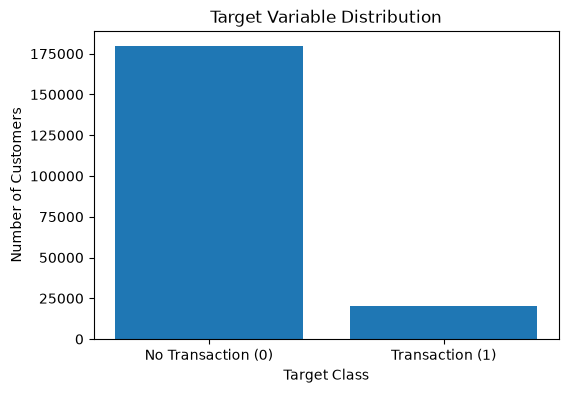

In [74]:
import matplotlib.pyplot as plt

target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No Transaction (0)", "Transaction (1)"], target_counts.values)
plt.title("Target Variable Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Customers")
plt.show()

## 4. Feature and Target Separation 

In [78]:
X=df.drop(columns=["ID_code","target"])
y=df["target"]

print(X.shape)
print(y.shape)

(200000, 200)
(200000,)


## 5. Train-Test Split

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("X_test:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

## 6. Logistic Regression Model

In [ ]:
from sklearn.linear_model import LogisticRegression
model_lr=LogisticRegression(max_iter=1000,random_state=42)
model_lr.fit(X_train,y_train)

y_pred_lr=model_lr.predict(X_test)
y_prob_lr=model_lr.predict_proba(X_test)[:,1]
print("Logistic Regression completed successfully.")

## 7. Logistic Regression Performance

In [ ]:
print("Logistic Regression Performance")
print("Accuracy:",accuracy_score(y_test,y_pred_lr))
print("precision:",precision_score(y_test,y_pred_lr))
print("Recall :",recall_score(y_test,y_pred_lr))
print("F1 score:",f1_score(y_test,y_pred_lr))
print("ROC-AUC :",roc_auc_score(y_test,y_prob_lr))

## 8. Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model_lr=RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)
model_lr.fit(X_train,y_train)
y_pred_rf=model_lr.predict(X_test)
y_prob_rf=model_lr.predict_proba(X_test)[:,1]
print("Random Forest completed successfully.")

## 9. Random Forest Performance

In [ ]:
print("Random Forest Performance")
print("Accuracy:",accuracy_score(y_test,y_pred_rf))
print("precision:",recall_score(y_test,y_pred_rf))
print("F1 score:",f1_score(y_test,y_pred_rf))
print("ROC-AUC:",roc_auc_score(y_test,y_prob_rf))

## 10. Decision Tree  

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model_dt=DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train,y_train)
y_pred_dt=model_dt.predict(X_test)
y_prob_dt=model_dt.predict_proba(X_test)[:,1]
print("Decision Tree completed successfully.")

## 11. Decision Tree Performance

In [ ]:
print("Decision Tree Performance")
print("Accuracy:",accuracy_score(y_test,y_pred_dt))
print("precision:",precision_score(y_test,y_pred_dt))
print("Recall:",recall_score(y_test,y_pred_dt))
print("F1 score:",f1_score(y_test,y_pred_dt))
print("ROC-AUC:",roc_auc_score(y_test,y_prob_dt))

## 12. Model Comparision

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Decision Tree"
    ],
    "Accuracy": [
        0.913375,
        0.8995,
        0.837925
    ],
    "Precision": [
        0.6829268293,
        0.0,
        0.2041796781
    ],
    "Recall": [
        0.2577114428,
        0.0,
        0.2114427861
    ],
    "F1 Score": [
        0.3742098609,
        0.0,
        0.2077477698
    ],
    "ROC-AUC": [
        0.8579774073,
        0.8198347306,
        0.5596819267
    ]
})

comparison

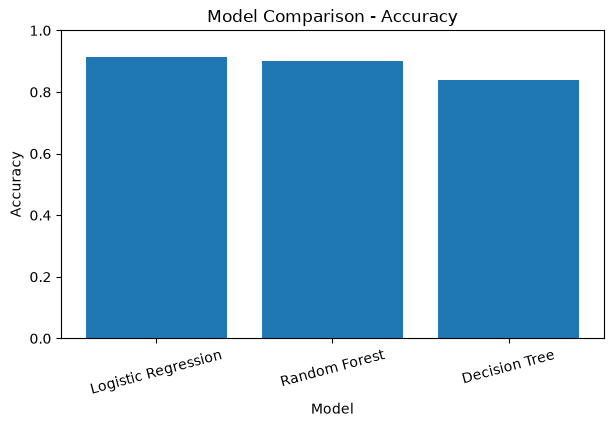

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(comparison["Model"], comparison["Accuracy"])
plt.title("Model Comparison - Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

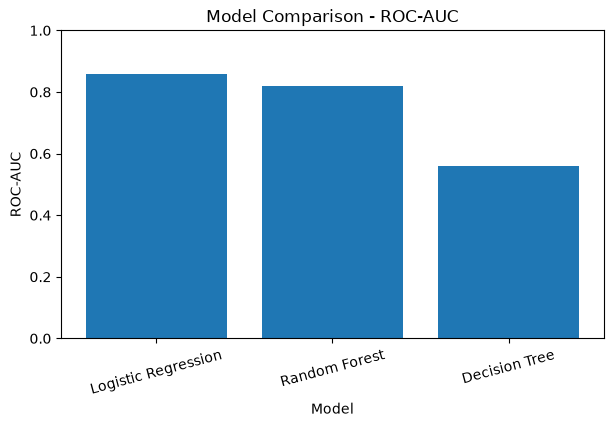

In [80]:
plt.figure(figsize=(7, 4))
plt.bar(comparison["Model"], comparison["ROC-AUC"])
plt.title("Model Comparison - ROC-AUC")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

## 13. Best Model for Production

In [ ]:
print("Best Model for Production: Logistic Regression")
print("Reason: Logistic Regression achieved the highest ROC-AUC and F1 Score among the evaluated models.")

## 14. Challenges Faced

In [ ]:
print("Challenges Faced")
print("1. The dataset contains anonymized feature names, so the meaning of individual features cannot be interpreted.")
print("2. The target variable is imbalanced, with fewer positive transactions than negative transactions.")
print("3. Multiple classification models were evaluated to identify the most suitable model for production.")
print("4. Logistic Regression showed the best overall performance among the evaluated models based on ROC-AUC and F1 Score.")

## 15. Final Conclusion

The objective of this project was to predict whether a customer is likely to make a future transaction. Multiple machine learning models were trained and evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

Among the evaluated models, Logistic Regression achieved the best overall performance, with the highest ROC-AUC and F1 Score. Therefore, Logistic Regression was selected as the best-performing model for production among the models evaluated in this project.

The project demonstrates how machine learning can be used to identify customers who are likely to make future transactions.